# 6BUIS017W CRM & CM with Business Intelligence – Individual Coursework (CWK1)
## Task 1: Data Preparation and Feature Engineering
**Market Analysis and Stock Segmentation Using RFM**

IIT ID: 20231076 | UoW ID: 20521398

**Static dataset:** the S&P 500 list changes over time, so the data was downloaded once (list retrieved on the date saved in `data/sp500_constituents.csv`) and saved in the repository. With `USE_SNAPSHOT = True` this notebook loads that saved data, so every run uses the same shares and prices. Set it to `False` to scrape Wikipedia and download from Yahoo Finance again.

## Setup


In [3]:
# Install the packages (versions are recorded for reproducibility)
!pip install -q yfinance==0.2.66 lxml

In [5]:
import os, sys, json, time
import datetime as dt
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Study settings (from the coursework brief) ----
START = '2021-01-01'      # first date requested
END = '2025-01-01'        # end date is EXCLUSIVE (last possible trading day = 31 Dec 2024)
BENCH = '^GSPC'           # S&P 500 benchmark index
WINDOW = 60               # latest 60 trading sessions for Frequency and Monetary
BASELINE = 20             # preceding 20 sessions for the volume baseline
MULT = 2                  # high-volume day: volume > 2 x baseline mean

USE_SNAPSHOT = True       # True = load the saved static dataset, False = download again

GITHUB_USER = 'shahlyfayeek'
REPO = 'crm-cwk1-stock-segmentation'
SNAPSHOT_URL = 'https://raw.githubusercontent.com/' + GITHUB_USER + '/' + REPO + '/main/data/'

DATA_DIR = 'data'
FIG_DIR = 'figures'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Package versions (required by the brief)
versions = {
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'yfinance': yf.__version__,
    'seaborn': sns.__version__,
    'matplotlib': __import__('matplotlib').__version__,
}
print(versions)

def snapshot_path(name):
    """Use the file in the Colab data folder if it is there, otherwise read it from the GitHub repo."""
    local = DATA_DIR + '/' + name
    if os.path.exists(local):
        return local
    return SNAPSHOT_URL + name

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'seaborn': '0.13.2', 'matplotlib': '3.10.0'}


## 1.1 Ticker selection and data acquisition

**Choices**
* Ticker list: current S&P 500 constituents table from Wikipedia, read with `pd.read_html` (as in Week 4).
* Price source: **`yfinance`** (chosen over YahooFinancials because it was used in the Week 1–5 notebooks and downloads many tickers at once).
* Prices are downloaded with `auto_adjust=False` so I keep both `Close` (split-adjusted) and `Adj Close` (split- and dividend-adjusted) plus `Volume`.
* Study period: 1 Jan 2021 to 1 Jan 2025, end date exclusive.

In [5]:
# --- 1.1a  S&P 500 ticker list ---
if USE_SNAPSHOT:
    sp500 = pd.read_csv(snapshot_path('sp500_constituents.csv'))
    retrieval_date = sp500['Retrieval_Date'].iloc[0]
    print('Loaded the saved ticker list, retrieved on:', retrieval_date)
else:
    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    # A User-Agent is needed, otherwise Wikipedia can return HTTP 403 (Week 4 notebook)
    table = pd.read_html(url, storage_options={'User-Agent': 'Mozilla/5.0'})
    sp500 = table[0].copy()

    retrieval_date = dt.datetime.now(dt.timezone.utc).strftime('%Y-%m-%d')
    print('Constituent list retrieved on:', retrieval_date, '(UTC)')

    # Yahoo uses '-' instead of '.' (BRK.B -> BRK-B)
    sp500['Ticker'] = sp500['Symbol'].str.replace('.', '-', regex=False)
    sp500['Retrieval_Date'] = retrieval_date
    sp500 = sp500[['Ticker', 'Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Retrieval_Date']]

print('Number of tickers on the list:', len(sp500))
print('Duplicate tickers on the list:', sp500['Ticker'].duplicated().sum())
sp500.to_csv(DATA_DIR + '/sp500_constituents.csv', index=False)
sp500.head()

Loaded the saved ticker list, retrieved on: 2026-11-14
Number of tickers on the list: 503
Duplicate tickers on the list: 0


,Ticker,Symbol,Security,GICS Sector,GICS Sub-Industry,Retrieval_Date
0,MMM,MMM,3M,Industrials,Industrial Conglomerates,2026-11-14
1,AOS,AOS,A. O. Smith,Industrials,Building Products,2026-11-14
2,ABT,ABT,Abbott Laboratories,Health Care,Health Care Equipment,2026-11-14
3,ABBV,ABBV,AbbVie,Health Care,Biotechnology,2026-11-14
4,ACN,ACN,Accenture,Information Technology,IT Consulting & Other Services,2026-11-14


In [6]:
# --- 1.1b  Daily prices and volume (shares + benchmark) ---
tickers = sp500['Ticker'].tolist()
all_symbols = tickers + [BENCH]

if USE_SNAPSHOT:
    adj_raw = pd.read_csv(snapshot_path('raw_adj_close.csv.gz'), index_col=0, parse_dates=True)
    close_raw = pd.read_csv(snapshot_path('raw_close.csv.gz'), index_col=0, parse_dates=True)
    vol_raw = pd.read_csv(snapshot_path('raw_volume.csv.gz'), index_col=0, parse_dates=True)
    source_used = 'saved snapshot of the Yahoo Finance download (list retrieved ' + retrieval_date + ')'
else:
    # Download in chunks of 100 tickers to reduce Yahoo rate-limit problems
    parts = []
    for i in range(0, len(all_symbols), 100):
        chunk = all_symbols[i:i + 100]
        parts.append(yf.download(chunk, start=START, end=END, auto_adjust=False, progress=False))
        time.sleep(1)
    raw = pd.concat(parts, axis=1)
    adj_raw = raw['Adj Close']
    close_raw = raw['Close']
    vol_raw = raw['Volume']
    source_used = 'live Yahoo Finance download'

for table_ in (adj_raw, close_raw, vol_raw):
    table_.index = pd.to_datetime(table_.index)
    table_.sort_index(inplace=True)

print('Data source used:', source_used)
print('Adj Close shape (dates x symbols):', adj_raw.shape)
print('First date:', adj_raw.index.min().date(), '| Last date:', adj_raw.index.max().date())

Data source used: saved snapshot of the Yahoo Finance download (list retrieved 2026-11-14)
Adj Close shape (dates x symbols): (1005, 504)
First date: 2021-01-04 | Last date: 2024-12-31


In [7]:
# --- 1.1c  Save the snapshots (static dataset) ---
adj_raw.to_csv(DATA_DIR + '/raw_adj_close.csv.gz', compression='gzip')
close_raw.to_csv(DATA_DIR + '/raw_close.csv.gz', compression='gzip')
vol_raw.to_csv(DATA_DIR + '/raw_volume.csv.gz', compression='gzip')

# Which symbols have no data at all?
failed = [t for t in all_symbols if (t not in adj_raw.columns) or adj_raw[t].isna().all()]
print('Symbols with no data at all:', failed)
pd.Series(failed, name='Symbol', dtype=str).to_csv(DATA_DIR + '/download_failures.csv', index=False)

Symbols with no data at all: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


## 1.2 Data validation and alignment

**Validation rules (a share is retained only if it passes all of them):**

| # | Rule | Why |
|---|---|---|
| R1 | Data downloaded | no data = nothing to analyse |
| R2 | Same history as the benchmark (first price on the first benchmark date) | unequal histories (new listings) give different numbers of weeks |
| R3 | No missing Adj Close, Close or Volume on any benchmark trading date | missing prices are **not filled** (the Week 4/5 `ffill/bfill` approach creates artificial zero returns and uses future prices) |
| R4 | All prices > 0 | non-positive prices are errors |
| R5 | Volume > 0 on every date | negative or zero volume for an S&P 500 share is a data error |

Duplicate dates and corporate actions (splits, dividends) are checked separately below.

In [8]:
# --- 1.2a  Benchmark and date checks ---
bench_adj = adj_raw[BENCH].dropna()
bench_dates = bench_adj.index
print('Benchmark trading days:', len(bench_dates))
print('Duplicate dates in the price table:', adj_raw.index.duplicated().sum())
print('Duplicate dates in the volume table:', vol_raw.index.duplicated().sum())
print('Dates outside the study period:', ((adj_raw.index < START) | (adj_raw.index >= END)).sum())
print('Dates not in the benchmark calendar:', len(adj_raw.index.difference(bench_dates)))
print('Benchmark non-positive prices:', (bench_adj <= 0).sum())

# Use the benchmark calendar for every share (identical dates)
adj = adj_raw.reindex(bench_dates)
close = close_raw.reindex(bench_dates)
vol = vol_raw.reindex(bench_dates)

Benchmark trading days: 1005
Duplicate dates in the price table: 0
Duplicate dates in the volume table: 0
Dates outside the study period: 0
Dates not in the benchmark calendar: 0
Benchmark non-positive prices: 0


In [9]:
# --- 1.2b  Apply the rules R1-R5 to every share and build the exclusion log ---
log_rows = []
for t in tickers:
    # R1 no data
    if (t not in adj.columns) or adj[t].isna().all():
        log_rows.append((t, 'R1 No data', 'No data downloaded'))
        continue

    # R2 unequal history: the first price is later than the first benchmark date
    first_valid = adj[t].first_valid_index()
    if first_valid > bench_dates[0]:
        log_rows.append((t, 'R2 Unequal history', 'First price on ' + str(first_valid.date())))

    # R3 missing values (only for shares with a full-length history)
    n_missing = int(adj[t].isna().sum() + close[t].isna().sum() + vol[t].isna().sum())
    if n_missing > 0 and first_valid == bench_dates[0]:
        log_rows.append((t, 'R3 Missing values', str(n_missing) + ' missing cells'))

    # R4 non-positive prices
    if (adj[t] <= 0).any() or (close[t] <= 0).any():
        log_rows.append((t, 'R4 Non-positive price', 'Adj Close or Close <= 0'))

    # R5 volume errors
    n_bad_volume = int((vol[t] <= 0).sum())
    if n_bad_volume > 0:
        log_rows.append((t, 'R5 Volume error', str(n_bad_volume) + ' day(s) with volume <= 0'))

exclusion_log = pd.DataFrame(log_rows, columns=['Ticker', 'Rule', 'Detail'])
excluded = set(exclusion_log['Ticker'])
included = [t for t in tickers if t not in excluded]

print('Tickers on the list      :', len(tickers))
print('Tickers excluded         :', len(excluded))
print('Tickers retained         :', len(included))
print()
print('Exclusions by rule:')
print(exclusion_log['Rule'].value_counts())

exclusion_log.to_csv(DATA_DIR + '/exclusion_log.csv', index=False)
pd.Series(included, name='Ticker').to_csv(DATA_DIR + '/included_tickers.csv', index=False)
exclusion_log

Tickers on the list      : 503
Tickers excluded         : 17
Tickers retained         : 486

Exclusions by rule:
Rule
R2 Unequal history    10
R1 No data             5
R5 Volume error        2
Name: count, dtype: int64


,Ticker,Rule,Detail
0,APP,R2 Unequal history,First price on 2021-04-15
1,COIN,R2 Unequal history,First price on 2021-04-14
2,CEG,R2 Unequal history,First price on 2022-01-19
3,EXE,R2 Unequal history,First price on 2021-02-10
4,FDXF,R1 No data,No data downloaded
5,FERG,R5 Volume error,27 day(s) with volume <= 0
6,GEHC,R2 Unequal history,First price on 2022-12-15
7,GEV,R2 Unequal history,First price on 2024-03-27
8,HONA,R1 No data,No data downloaded
9,Q,R1 No data,No data downloaded


In [10]:
# --- 1.2c  Corporate action checks ---
adj_in = adj[included]
close_in = close[included]
vol_in = vol[included]

# (i) Shares whose Adj Close is below Close at the start: dividends are being adjusted
ratio_first = adj_in.iloc[0] / close_in.iloc[0]
print('Shares where Adj Close < Close at the start (dividend adjustment):',
      int((ratio_first < 0.9999).sum()), 'of', len(included))

# (ii) Very large one-day moves in Close can mean an unadjusted split
close_ret = close_in.pct_change(fill_method=None)
adj_ret = adj_in.pct_change(fill_method=None)
flag_rows = []
for t in included:
    big_days = close_ret.index[close_ret[t].abs() > 0.35]
    for d in big_days:
        flag_rows.append((t, d.date(), round(close_ret.loc[d, t], 3), round(adj_ret.loc[d, t], 3)))
flag_table = pd.DataFrame(flag_rows, columns=['Ticker', 'Date', 'Close_return', 'AdjClose_return'])
print('Days with an absolute daily Close move above 35%:', len(flag_table))
flag_table.to_csv(DATA_DIR + '/corporate_action_flags.csv', index=False)
flag_table

Shares where Adj Close < Close at the start (dividend adjustment): 398 of 486
Days with an absolute daily Close move above 35%: 15


,Ticker,Date,Close_return,AdjClose_return
0,BIIB,2021-06-07,0.383,0.383
1,BIIB,2022-09-28,0.399,0.399
2,BE,2021-10-25,0.371,0.371
3,BE,2024-11-15,0.592,0.592
4,CVNA,2022-08-05,0.401,0.401
5,CVNA,2022-11-04,-0.390,-0.390
6,CVNA,2022-12-07,-0.429,-0.429
7,CVNA,2023-01-12,0.460,0.460
8,CVNA,2023-06-08,0.560,0.560
9,CVNA,2023-07-19,0.402,0.402


In [11]:
# (iii) Check Yahoo's recorded stock splits for the flagged shares only
split_rows = []
for t in sorted(flag_table['Ticker'].unique()):
    try:
        s = yf.Ticker(t).splits
        s.index = pd.to_datetime(s.index).tz_localize(None)
        s = s[(s.index >= START) & (s.index < END)]
        for d, ratio in s.items():
            split_rows.append((t, d.date(), ratio))
    except Exception as e:
        print(t, 'split lookup failed:', e)

split_table = pd.DataFrame(split_rows, columns=['Ticker', 'Split_date', 'Split_ratio'])
split_table.to_csv(DATA_DIR + '/splits_found.csv', index=False)
print('Splits found for flagged shares in the period:')
split_table

Splits found for flagged shares in the period:


,Ticker,Split_date,Split_ratio
0,DXCM,2022-06-13,4.0
1,SMCI,2024-10-01,10.0


**Corporate actions**
Splits and dividends change a share's price without changing the value of the company, so I checked that the prices were adjusted for them. Adj Close is adjusted for both and Close for splits only. 398 of 486 shares have Adj Close below Close at the start, which shows the dividends are included. I looked for one-day moves above 35% because an unadjusted split would show up like that. There were 15, but Close and Adj Close gave the same return on each, and none fell on the two split dates Yahoo gave (DXCM and SMCI). So they are real price moves, not data problems. I use Adj Close for returns and beta, and Close x Volume for Monetary. The benchmark is a price index without dividends, so its returns are slightly lower than a total return, which is a small limitation for beta.

**Exclusions**
17 of 503 tickers were excluded: 5 had no data (R1), 10 listed after January 2021 so have a shorter history (R2), and 2 (FERG and SW) had days with zero volume (R5). I did not fill any missing prices.

**Survivorship bias**
The share list is today's S&P 500 but I use it for 2021-2024. Companies that were removed from the index in that time are missing, and companies that joined later are included. This favours winners, so average returns look higher and risk lower than they really were.

## 1.3.1 Mean weekly return
* Friday-ending weeks: `resample('W-FRI').last()` (final available trading price of the week, so holiday-shortened weeks are kept).
* Weekly return = adjusted close at the end of this week / adjusted close at the end of the previous week - 1.
* **Incomplete first and final calendar weeks are excluded.** A week is kept only if its Monday is on or after the start date and its Friday is before the exclusive end date.
* Mean weekly return = arithmetic mean over the full period.

In [12]:
# --- Weekly prices for shares and benchmark ---
adj_week = adj_in.resample('W-FRI').last()
bench_week = bench_adj.resample('W-FRI').last()

# A week is complete if its Monday is on or after START and its Friday is before END
week_monday = adj_week.index - pd.Timedelta(days=4)
complete = (week_monday >= pd.Timestamp(START)) & (adj_week.index < pd.Timestamp(END))
print('Weeks removed as incomplete:', [d.date() for d in adj_week.index[~complete]])

adj_week = adj_week[complete]
bench_week = bench_week[complete]
print('First complete week:', adj_week.index[0].date(), '| Last complete week:', adj_week.index[-1].date())
print('Number of complete weekly prices:', len(adj_week))

# Weekly returns (no filling: fill_method=None). The first week has no previous week.
weekly_ret = adj_week.pct_change(fill_method=None).iloc[1:]
bench_ret = bench_week.pct_change(fill_method=None).iloc[1:]

# Common week labels
print('Identical week labels for shares and benchmark:', weekly_ret.index.equals(bench_ret.index))
print('Missing weekly returns in the share table:', int(weekly_ret.isna().sum().sum()))
print('Missing weekly returns for the benchmark:', int(bench_ret.isna().sum()))
print('Number of weekly return observations:', len(bench_ret))

Weeks removed as incomplete: [datetime.date(2025, 1, 3)]
First complete week: 2021-01-08 | Last complete week: 2024-12-27
Number of complete weekly prices: 208
Identical week labels for shares and benchmark: True
Missing weekly returns in the share table: 0
Missing weekly returns for the benchmark: 0
Number of weekly return observations: 207


In [13]:
# --- Mean weekly return (arithmetic mean) ---
mean_ret = pd.DataFrame({'Mean_Weekly_Return': weekly_ret.mean(),
                         'Aligned_Weeks': weekly_ret.notna().sum()})
mean_ret.index.name = 'Ticker'
print('Aligned weekly observations per share (unique values):', mean_ret['Aligned_Weeks'].unique())

mean_ret.to_csv(DATA_DIR + '/mean_weekly_return.csv')

weekly_all = weekly_ret.copy()
weekly_all[BENCH] = bench_ret
weekly_all.to_csv(DATA_DIR + '/weekly_returns.csv.gz', compression='gzip')
mean_ret.head()

Aligned weekly observations per share (unique values): [207]


,Mean_Weekly_Return,Aligned_Weeks
Ticker,,
MMM,0.001142,207
AOS,0.001991,207
ABT,0.000971,207
ABBV,0.003749,207
ACN,0.002376,207


In [14]:
# --- Check the return formula and the mean by hand on one share ---
check = included[0]
print('Check share:', check)

prices = adj_week[check].tail(4)
by_hand = (prices / prices.shift(1) - 1).dropna()
print('By-hand weekly returns:')
print(by_hand.round(5).to_string())
print('Table values:')
print(weekly_ret[check].tail(3).round(5).to_string())
assert np.allclose(by_hand.values, weekly_ret[check].tail(3).values)

print('Mean weekly return, by hand :', round(weekly_ret[check].sum() / len(weekly_ret), 6))
print('Mean weekly return, table   :', round(mean_ret.loc[check, 'Mean_Weekly_Return'], 6))

Check share: MMM
By-hand weekly returns:
Date
2024-12-13   -0.02397
2024-12-20   -0.00493
2024-12-27    0.00696
Freq: W-FRI
Table values:
Date
2024-12-13   -0.02397
2024-12-20   -0.00493
2024-12-27    0.00696
Freq: W-FRI
Mean weekly return, by hand : 0.001142
Mean weekly return, table   : 0.001142


## 1.3.2 Weekly beta
Weekly beta = covariance(share weekly returns, benchmark weekly returns) / variance(benchmark weekly returns), using the full study period on matched week labels (both use the sample formula, ddof = 1). No missing weeks are filled and no multi-week change is treated as a one-week return.

In [15]:
beta_list = []
weeks_list = []
for t in included:
    share = weekly_ret[t]
    beta = share.cov(bench_ret) / bench_ret.var()        # cov() lines the two series up by week label
    n_weeks = int((share.notna() & bench_ret.notna()).sum())
    beta_list.append(beta)
    weeks_list.append(n_weeks)

beta_df = pd.DataFrame({'Weekly_Beta': beta_list, 'Aligned_Weeks': weeks_list}, index=included)
beta_df.index.name = 'Ticker'
print('Aligned weekly observations used for beta:', beta_df['Aligned_Weeks'].unique())
print('Benchmark weekly return variance:', round(bench_ret.var(), 8))
beta_df.to_csv(DATA_DIR + '/weekly_beta.csv')
beta_df.head()

Aligned weekly observations used for beta: [207]
Benchmark weekly return variance: 0.00049218


,Weekly_Beta,Aligned_Weeks
Ticker,,
MMM,0.869079,207
AOS,1.042805,207
ABT,0.583543,207
ABBV,0.425366,207
ACN,1.143299,207


In [16]:
# --- Check: beta from the slope of a fitted straight line ---
check = included[0]
slope = np.polyfit(bench_ret.values, weekly_ret[check].values, 1)[0]
print('Check share:', check)
print('Beta (covariance / variance):', round(beta_df.loc[check, 'Weekly_Beta'], 6))
print('Beta (regression slope)     :', round(slope, 6))
assert abs(slope - beta_df.loc[check, 'Weekly_Beta']) < 1e-8

Check share: MMM
Beta (covariance / variance): 0.869079
Beta (regression slope)     : 0.869079


## 1.4 Adapted RFM calculations

RFM is adapted from customer purchasing to **share trading activity**. It does not measure company value, loyalty or profitability.

* **Observation date** = final common completed trading date of the study period.
* **High-volume day:** volume > 2 x the mean volume of the **preceding 20 trading sessions, excluding the day being tested** (`shift(1)` then `rolling(20).mean()`). The threshold is calculated separately for every share and every day.
* **Recency (R):** calendar days from the latest high-volume day (in the valid history) to the observation date. Same day = 0. If there is no event, R is left missing (not 0).
* **Frequency (F):** number of high-volume days in the latest 60 sessions ending on the observation date.
* **Monetary (M):** sum of `Close x Volume` over those 60 sessions (USD, approximate traded value).

In [17]:
# Observation date = last date on which every retained share has data
obs_date = close_in.dropna(how='any').index.max()
print('Observation date:', obs_date.date())

# Use data up to the observation date only
vol_use = vol_in.loc[:obs_date]
close_use = close_in.loc[:obs_date]

# Mean volume of the previous 20 sessions (shift(1) leaves the current day out), for every share and day
baseline = vol_use.shift(1).rolling(BASELINE).mean()
threshold = MULT * baseline

# A high-volume day: volume is greater than the threshold (days without a full baseline are never events)
high_volume = vol_use > threshold

# History check: 20 sessions of baseline for each of the 60 window days = 80 sessions
sessions = vol_use.notna().sum()
print('Shares with at least', WINDOW + BASELINE, 'sessions of history:', int((sessions >= WINDOW + BASELINE).sum()), 'of', len(included))

Observation date: 2024-12-31
Shares with at least 80 sessions of history: 486 of 486


### 1.4.1 Recency

In [18]:
recency_list = []
last_event_list = []
for t in included:
    event_days = high_volume.index[high_volume[t]]          # all high-volume days of this share
    if len(event_days) == 0:
        recency_list.append(np.nan)                          # no event: missing, not 0
        last_event_list.append(None)
    else:
        recency_list.append((obs_date - event_days[-1]).days)
        last_event_list.append(event_days[-1].date())

recency = pd.DataFrame({'Recency': recency_list, 'Latest_Event_Date': last_event_list}, index=included)
recency.index.name = 'Ticker'
print('Shares with R missing (no high-volume event):', int(recency['Recency'].isna().sum()))

# Shares with no event cannot go into RFM clustering: log them
no_event = recency[recency['Recency'].isna()]
if len(no_event) > 0:
    extra = pd.DataFrame({'Ticker': no_event.index,
                          'Rule': 'RFM: no event',
                          'Detail': 'No high-volume day in valid history, R missing, excluded from RFM clustering (not set to 0)'})
    exclusion_log = pd.concat([exclusion_log, extra], ignore_index=True)
    exclusion_log.to_csv(DATA_DIR + '/exclusion_log.csv', index=False)

recency.to_csv(DATA_DIR + '/recency.csv')
recency.head()

Shares with R missing (no high-volume event): 0


,Recency,Latest_Event_Date
Ticker,,
MMM,11,2024-12-20
AOS,11,2024-12-20
ABT,11,2024-12-20
ABBV,11,2024-12-20
ACN,11,2024-12-20


### 1.4.2 Frequency

In [19]:
# Count the high-volume days in the latest 60 sessions
frequency = pd.DataFrame({'Frequency': high_volume.tail(WINDOW).sum()})
frequency.index.name = 'Ticker'
print(frequency['Frequency'].describe().round(2))
frequency.to_csv(DATA_DIR + '/frequency.csv')
frequency.head()

count    486.00
mean       2.99
std        1.33
min        0.00
25%        2.00
50%        3.00
75%        4.00
max        8.00
Name: Frequency, dtype: float64


,Frequency
Ticker,
MMM,4
AOS,2
ABT,1
ABBV,3
ACN,2


### 1.4.3 Monetary

In [20]:
# Sum of Close x Volume over the latest 60 sessions (USD)
monetary = pd.DataFrame({'Monetary': (close_use.tail(WINDOW) * vol_use.tail(WINDOW)).sum()})
monetary.index.name = 'Ticker'
print('Monetary is in USD (sum of Close x Volume over 60 sessions)')
print(monetary['Monetary'].describe().apply(lambda x: '{:,.0f}'.format(x)))
monetary.to_csv(DATA_DIR + '/monetary.csv')
monetary.head()

Monetary is in USD (sum of Close x Volume over 60 sessions)
count                  486
mean        39,404,191,889
std        129,138,833,233
min          1,297,482,617
25%         10,195,173,392
50%         16,683,821,505
75%         32,276,893,044
max      1,847,697,379,222
Name: Monetary, dtype: object


,Monetary
Ticker,
MMM,2.599146e+10
AOS,4.748980e+09
ABT,3.523027e+10
ABBV,6.837054e+10
ACN,5.199430e+10


## 1.5 Metric interpretation and supporting evidence

### Worked example and checks
The first cell shows every RFM step for one share. The second cell checks the threshold alignment and tests the rules on small made-up series (the numbers from the brief), including the boundary cases.

In [21]:
# --- Worked example for one share ---
example = recency['Recency'].dropna().index[0]
lines = []

example_table = pd.DataFrame({'Close': close_use[example],
                              'Volume': vol_use[example],
                              'Mean_prev_20': baseline[example].round(0),
                              'Threshold_2x': threshold[example].round(0),
                              'High_volume_day': high_volume[example]}).tail(8)
print(example_table.to_string())
example_table.to_csv(DATA_DIR + '/worked_example.csv')

lines.append('Worked example share: ' + example + ' | Observation date: ' + str(obs_date.date()))

# Recency by hand
event_days = high_volume.index[high_volume[example]]
last_event = event_days[-1]
recency_hand = (obs_date - last_event).days
lines.append('Latest high-volume day: ' + str(last_event.date()))
lines.append('Recency = observation date - event date = ' + str(recency_hand) + ' calendar days')

# Frequency by hand (latest 60 sessions)
window_flags = high_volume[example].tail(WINDOW)
frequency_hand = int(window_flags.sum())
lines.append('60-session window runs from ' + str(window_flags.index[0].date()) + ' to ' + str(window_flags.index[-1].date()))
lines.append('Frequency = high-volume days in the window = ' + str(frequency_hand))

# Monetary by hand
daily_value = close_use[example].tail(WINDOW) * vol_use[example].tail(WINDOW)
monetary_hand = daily_value.sum()
lines.append('Monetary = sum of 60 daily Close x Volume = USD {:,.0f}'.format(monetary_hand))

# The by-hand numbers must match the tables from sections 1.4.1 - 1.4.3
assert recency_hand == recency.loc[example, 'Recency']
assert frequency_hand == frequency.loc[example, 'Frequency']
assert abs(monetary_hand - monetary.loc[example, 'Monetary']) < 1
lines.append('By-hand R, F and M match the tables above.')
print()
print('\n'.join(lines))

                 Close   Volume  Mean_prev_20  Threshold_2x  High_volume_day
Date                                                                        
2024-12-19  127.129997  3038100     2960665.0     5921330.0            False
2024-12-20  129.279999  8351300     3027540.0     6055080.0             True
2024-12-23  128.979996  2067400     3317865.0     6635730.0            False
2024-12-24  130.360001   803200     3268615.0     6537230.0            False
2024-12-26  131.179993  1484900     3055040.0     6110080.0            False
2024-12-27  130.179993  1842600     2975270.0     5950540.0            False
2024-12-30  129.130005  2154000     2938420.0     5876840.0            False
2024-12-31  129.089996  2220300     2965205.0     5930410.0            False

Worked example share: MMM | Observation date: 2024-12-31
Latest high-volume day: 2024-12-20
Recency = observation date - event date = 11 calendar days
60-session window runs from 2024-10-07 to 2024-12-31
Frequency = high-volume d

In [22]:
# --- Check 1: threshold alignment (the baseline uses the 20 sessions BEFORE the day) ---
v = vol_use[example]
pos = len(v) - 10                                   # test a day 10 sessions before the end
manual_baseline = v.iloc[pos - BASELINE:pos].mean() # sessions pos-20 ... pos-1 (current day excluded)
lines.append('Baseline from rolling code: ' + str(round(baseline[example].iloc[pos], 2)) + ' | by hand: ' + str(round(manual_baseline, 2)))
assert abs(baseline[example].iloc[pos] - manual_baseline) < 1e-6

# --- Check 2: made-up data (100 trading days) ---
days = pd.bdate_range('2024-01-01', periods=100)
price = pd.Series(100.0, index=days)

# (a) the brief's numbers: baseline about 1 million shares
vol_a = pd.Series(1_000_000.0, index=days)
vol_a.iloc[85] = 2_000_000    # exactly 2 x baseline -> NOT an event (it must be greater)
vol_a.iloc[90] = 1_800_000    # below the threshold -> NOT an event
vol_a.iloc[95] = 2_500_000    # above the threshold -> event
event_a = vol_a > 2 * vol_a.shift(1).rolling(BASELINE).mean()
assert (not event_a.iloc[85]) and (not event_a.iloc[90]) and event_a.iloc[95]
assert event_a.tail(WINDOW).sum() == 1
assert (days[-1] - days[event_a][-1]).days == (days[-1] - days[95]).days
lines.append('Test (a): 2.0m and 1.8m are not events, 2.5m is. F = 1, R = ' + str((days[-1] - days[95]).days))

# (b) an event on the observation date gives R = 0
vol_b = pd.Series(1_000_000.0, index=days)
vol_b.iloc[-1] = 3_000_000
event_b = vol_b > 2 * vol_b.shift(1).rolling(BASELINE).mean()
assert (days[-1] - days[event_b][-1]).days == 0
lines.append('Test (b): an event on the observation date gives R = 0')

# (c) no event: nothing is flagged, so R stays missing (not 0)
vol_c = pd.Series(1_000_000.0, index=days)
event_c = vol_c > 2 * vol_c.shift(1).rolling(BASELINE).mean()
assert event_c.sum() == 0
lines.append('Test (c): no event gives F = 0 and R missing')

# (d) Monetary: 100 USD x 2 million shares = 200 million a day, x 60 days = 12 billion
vol_d = pd.Series(2_000_000.0, index=days)
monetary_d = (price.tail(WINDOW) * vol_d.tail(WINDOW)).sum()
assert monetary_d == 60 * 200_000_000
lines.append('Test (d): Monetary = USD {:,.0f}'.format(monetary_d))

# (e) history: 60 window days each need 20 earlier sessions
lines.append('Test (e): at least ' + str(WINDOW + BASELINE) + ' sessions are needed; all retained shares have ' + str(int(sessions.min())) + ' or more')
assert sessions.min() >= WINDOW + BASELINE

print('\n'.join(lines[-6:]))
with open(DATA_DIR + '/validation_checks.txt', 'w') as f:
    f.write('\n'.join(lines))

Baseline from rolling code: 2890235.0 | by hand: 2890235.0
Test (a): 2.0m and 1.8m are not events, 2.5m is. F = 1, R = 4
Test (b): an event on the observation date gives R = 0
Test (c): no event gives F = 0 and R missing
Test (d): Monetary = USD 12,000,000,000
Test (e): at least 80 sessions are needed; all retained shares have 1005 or more


### Feature table and interpretation

**What each metric captures (and does not)**

| Metric | Captures | Does NOT capture |
|---|---|---|
| Mean weekly return | Average weekly price + dividend change over 2021-2024 | Compounded return, risk, or future return |
| Weekly beta | Sensitivity of the share's weekly returns to the S&P 500 weekly returns | Total risk, diversification (dependencies between shares matter too) |
| Recency | How many calendar days ago the latest unusually high-volume day was | Whether the news was good or bad |
| Frequency | How many unusually high-volume days in the last 60 sessions | Number of trades or total shares traded |
| Monetary | Approximate USD traded value (Close x Volume) over 60 sessions | Market capitalisation, profit, or net investment inflow; it is only a liquidity proxy |

In [23]:
# --- Feature table: one row per included share ---
features = mean_ret[['Mean_Weekly_Return']]
features = features.join(beta_df)
features = features.join(recency[['Recency']])
features = features.join(frequency)
features = features.join(monetary)
features = features.join(sp500.set_index('Ticker')[['Security', 'GICS Sector']])

features['Observation_Date'] = obs_date.date()
model_cols = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']
features['In_Common_Valid_Set'] = features[model_cols].notna().all(axis=1)
features = features[['Security', 'GICS Sector', 'Mean_Weekly_Return', 'Weekly_Beta', 'Aligned_Weeks',
                     'Recency', 'Frequency', 'Monetary', 'Observation_Date', 'In_Common_Valid_Set']]
features.to_csv(DATA_DIR + '/feature_table.csv')

print('Rows in the feature table (one per included share):', len(features))
print('Shares in the common valid set for clustering   :', int(features['In_Common_Valid_Set'].sum()))
features.head()

Rows in the feature table (one per included share): 486
Shares in the common valid set for clustering   : 486


,Security,GICS Sector,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks,Recency,Frequency,Monetary,Observation_Date,In_Common_Valid_Set
Ticker,,,,,,,,,,
MMM,3M,Industrials,0.001142,0.869079,207,11,4,2.599146e+10,2024-12-31,True
AOS,A. O. Smith,Industrials,0.001991,1.042805,207,11,2,4.748980e+09,2024-12-31,True
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207,11,1,3.523027e+10,2024-12-31,True
ABBV,AbbVie,Health Care,0.003749,0.425366,207,11,3,6.837054e+10,2024-12-31,True
ACN,Accenture,Information Technology,0.002376,1.143299,207,11,2,5.199430e+10,2024-12-31,True


In [24]:
# Feature summaries
summary = features[model_cols].describe().T
summary['skew'] = features[model_cols].skew()
pd.options.display.float_format = '{:,.4f}'.format
summary.to_csv(DATA_DIR + '/feature_summary.csv')
summary

,count,mean,std,min,25%,50%,75%,max,skew
Mean_Weekly_Return,486.0000,0.0029,0.0027,-0.0045,0.0012,0.0026,0.0042,0.0178,0.8675
Weekly_Beta,486.0000,0.9737,0.4073,0.0555,0.6666,0.9506,1.1795,3.7786,1.1036
Recency,486.0000,20.4074,21.3424,4.0000,11.0000,11.0000,14.7500,222.0000,3.6458
Frequency,486.0000,2.9897,1.3308,0.0000,2.0000,3.0000,4.0000,8.0000,0.4247
Monetary,486.0000,"39,404,191,889.2078","129,138,833,232.9717","1,297,482,617.0479","10,195,173,392.2705","16,683,821,504.6230","32,276,893,043.8724","1,847,697,379,221.8428",11.6838


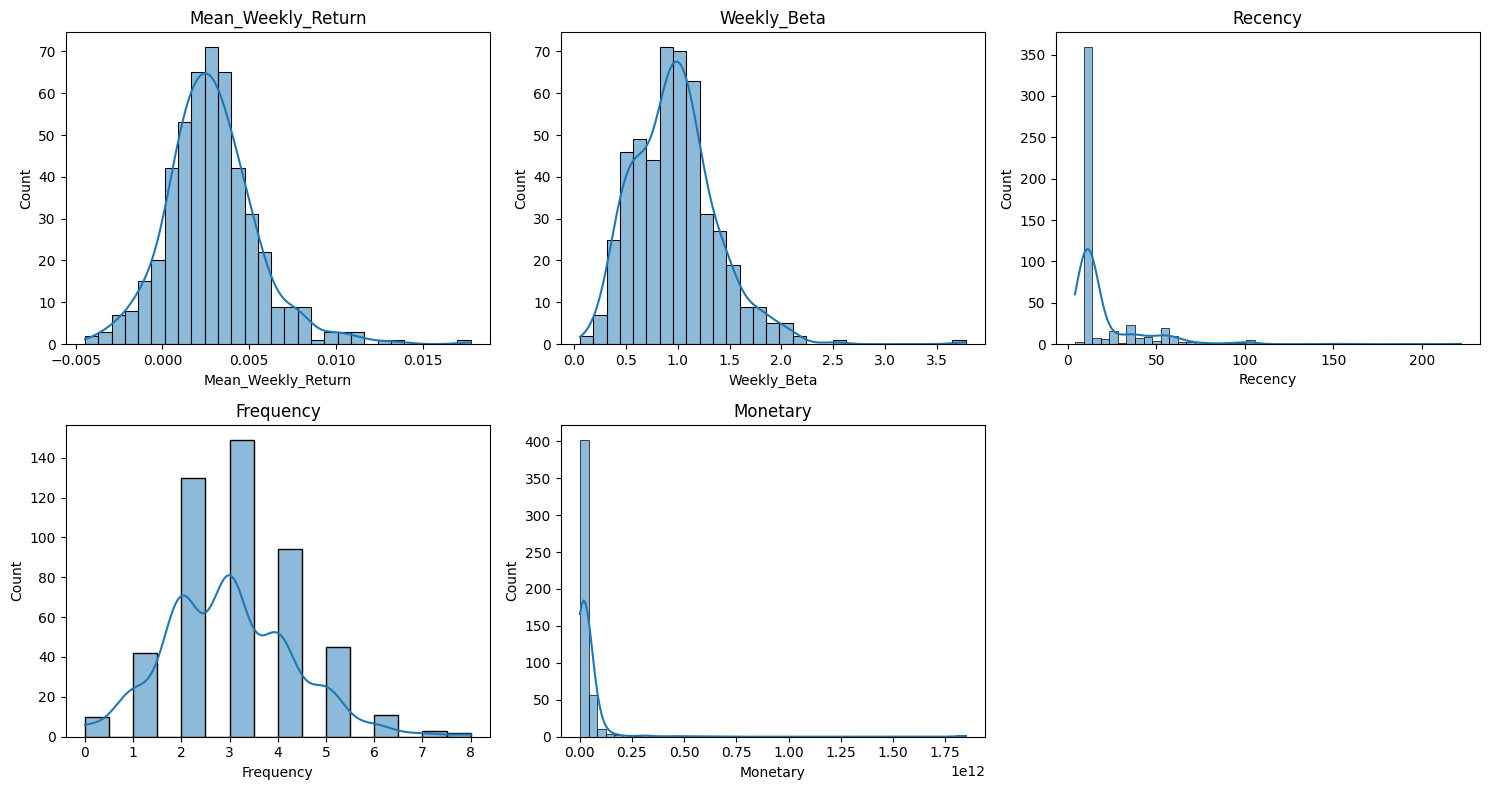

In [25]:
# Distributions (skew and outliers matter for clustering in Task 2)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), model_cols):
    sns.histplot(features[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR + '/feature_histograms.png', dpi=150)
plt.show()

In [26]:
# Sector counts of the retained shares (needed later for sector composition)
print(features['GICS Sector'].value_counts())

# Final evidence summary
print()
print('Constituent list retrieved :', retrieval_date)
print('Data source used           :', source_used)
print('Study period               :', START, 'to', END, '(end exclusive)')
print('Tickers listed             :', len(tickers))
print('Excluded by validation     :', len(excluded))
print('Retained shares            :', len(included))
print('Weekly observations        :', len(bench_ret))
print('Observation date           :', obs_date.date())
print('Shares in common valid set :', int(features['In_Common_Valid_Set'].sum()))

# Record of the run
metadata = {
    'constituent_list_url': 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies',
    'constituent_retrieval_date': retrieval_date,
    'data_source': source_used,
    'price_library': 'yfinance ' + yf.__version__,
    'study_start': START, 'study_end_exclusive': END,
    'benchmark': BENCH,
    'observation_date': str(obs_date.date()),
    'rfm_settings': {'window_sessions': WINDOW, 'baseline_sessions': BASELINE, 'multiplier': MULT},
    'package_versions': versions,
    'tickers_listed': len(tickers), 'tickers_excluded': len(excluded), 'tickers_retained': len(included),
    'weekly_observations': int(len(bench_ret)),
}
with open(DATA_DIR + '/run_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2, default=str)
with open('package_versions.txt', 'w') as f:
    f.write(json.dumps(versions, indent=2))

GICS Sector
Industrials               78
Information Technology    74
Financials                74
Health Care               58
Consumer Discretionary    47
Consumer Staples          32
Utilities                 30
Real Estate               30
Materials                 23
Communication Services    20
Energy                    20
Name: count, dtype: int64

Constituent list retrieved : 2026-11-14
Data source used           : saved snapshot of the Yahoo Finance download (list retrieved 2026-11-14)
Study period               : 2021-01-01 to 2025-01-01 (end exclusive)
Tickers listed             : 503
Excluded by validation     : 17
Retained shares            : 486
Weekly observations        : 207
Observation date           : 2024-12-31
Shares in common valid set : 486


**Interpretation of the features**

* **Typical values:** The average weekly return is about 0.29% (median 0.26%) and the average weekly beta is about 0.97, so the typical share moves roughly in line with the S&P 500. Beta ranges from 0.06 to 3.78, so a few shares are far more volatile than the market. Recency has a median of 11 days and Frequency a median of 3 high-volume days in the last 60 sessions.
* **Skewness:** Monetary is very skewed (skew 11.7): the mean is about 39 billion USD but the median is about 17 billion, and the largest share is about 1,848 billion. A few heavily traded shares dominate. Recency is also skewed (3.6) because most shares share the same recent date and a few have been quiet for much longer. Monetary will be log-transformed in Task 2 so these large values do not dominate the clustering.
* **Recency is dominated by one date:** Most shares have their latest high-volume day on 20 December 2024, a day when futures and options expired and volume rose across the whole market. So Recency here reflects a market-wide event more than news about each company.
* **Descriptive, not a signal:** A high Frequency or a recent event only describes past trading activity. It does not say whether the news was good or bad, and it is not a reason to buy or sell.
* **Limitations:** Close and Adj Close are on different bases (splits only vs splits and dividends). The benchmark is a price index without dividends, so beta is slightly affected. The share list has survivorship bias. Volume depends on things like index rebalancing and options expiry. About four years of weekly data (207 weeks) is a sample, not the full picture, so beta and mean return are estimates.

# Task 2: Stock Segmentation and Sensitivity Analysis

Four baseline solutions are built: Ward agglomerative clustering and k-means, each fitted separately to (1) the risk-return features (mean weekly return, weekly beta) and (2) the trading activity features (R, F, log1p(M)). The shares come from the common valid set in the Task 1 feature table.

In [3]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
import sklearn, scipy

SEED = 42                # random seed used for every random step
K_RANGE = range(2, 9)    # cluster counts compared: 2 to 8

print('scikit-learn', sklearn.__version__, '| scipy', scipy.__version__)

scikit-learn 1.6.1 | scipy 1.16.3


## 2.1 Feature preparation
* The feature table from Task 1 has one row per retained share. Only shares in the common valid set (all five features present) are used, so every model clusters the same shares.
* Skew is measured for each feature. Outliers are counted with the IQR rule (a value more than 1.5 x IQR beyond the quartiles).
* `log1p` is applied to Monetary as required. The other skewed variables are examined below.

In [6]:
# --- 2.1a  Load the feature table and keep the common valid share set ---
feat = pd.read_csv(snapshot_path('feature_table.csv'), index_col=0)
print('Rows in the feature table:', len(feat))
feat = feat[feat['In_Common_Valid_Set']].copy()
print('Shares in the common valid set:', len(feat))

feat['Return_pct'] = feat['Mean_Weekly_Return'] * 100      # mean weekly return in percent (easier to read in profiles)

cols = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']
feat[cols].describe().round(4)

Rows in the feature table: 486
Shares in the common valid set: 486


,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary
count,486.0000,486.0000,486.0000,486.0000,4.860000e+02
mean,0.0029,0.9737,20.4074,2.9897,3.940419e+10
std,0.0027,0.4073,21.3424,1.3308,1.291388e+11
min,-0.0045,0.0555,4.0000,0.0000,1.297483e+09
25%,0.0012,0.6666,11.0000,2.0000,1.019517e+10
50%,0.0026,0.9506,11.0000,3.0000,1.668382e+10
75%,0.0042,1.1795,14.7500,4.0000,3.227689e+10
max,0.0178,3.7786,222.0000,8.0000,1.847697e+12


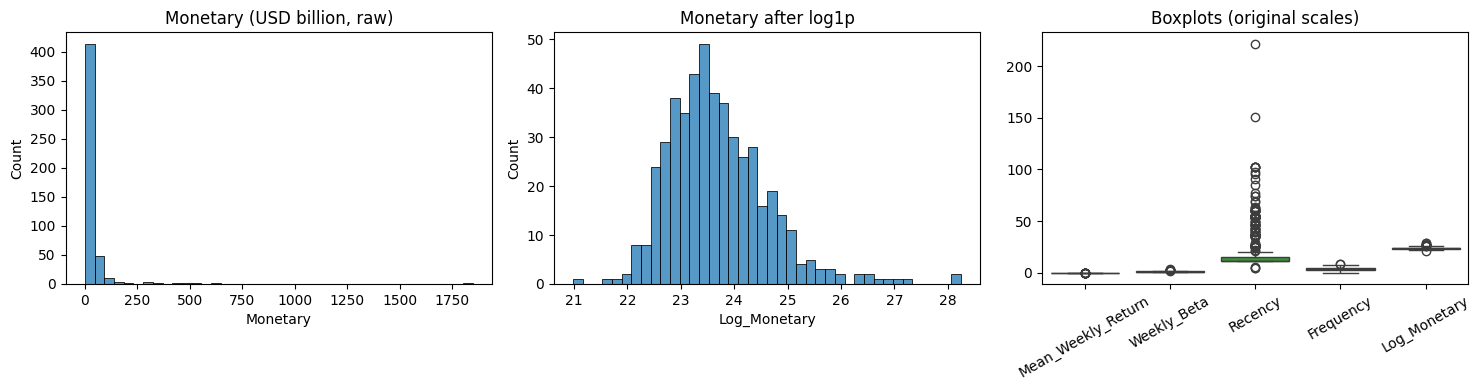

,Skew,Outliers_IQR
Feature,,
Mean_Weekly_Return,0.87,15
Weekly_Beta,1.10,10
Recency,3.65,115
Frequency,0.42,2
Monetary (raw),11.68,45
Log_Monetary = log1p(M),1.08,13
"log1p(Recency) (comparison only, not used)",1.58,113


In [7]:
# --- 2.1b  Skew and outliers ---
feat['Log_Monetary'] = np.log1p(feat['Monetary'])

series_to_check = {
    'Mean_Weekly_Return': feat['Mean_Weekly_Return'],
    'Weekly_Beta': feat['Weekly_Beta'],
    'Recency': feat['Recency'],
    'Frequency': feat['Frequency'],
    'Monetary (raw)': feat['Monetary'],
    'Log_Monetary = log1p(M)': feat['Log_Monetary'],
    'log1p(Recency) (comparison only, not used)': np.log1p(feat['Recency']),
}
rows = []
for name, s in series_to_check.items():
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    rows.append((name, s.skew(), n_out))
skew_table = pd.DataFrame(rows, columns=['Feature', 'Skew', 'Outliers_IQR']).set_index('Feature')
skew_table.to_csv(DATA_DIR + '/feature_skew_outliers.csv')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(feat['Monetary'] / 1e9, bins=40, ax=axes[0])
axes[0].set_title('Monetary (USD billion, raw)')
sns.histplot(feat['Log_Monetary'], bins=40, ax=axes[1])
axes[1].set_title('Monetary after log1p')
sns.boxplot(data=feat[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Log_Monetary']], ax=axes[2])
axes[2].set_title('Boxplots (original scales)')
axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR + '/2_1_skew_and_outliers.png', dpi=150)
plt.show()

skew_table.round(2)

In [8]:
# --- 2.1c  Two separate feature matrices on the same shares, standardised separately ---
X_rr_raw = feat[['Mean_Weekly_Return', 'Weekly_Beta']]                # risk and return
X_act_raw = feat[['Recency', 'Frequency', 'Log_Monetary']]            # trading activity (R, F, log1p(M))
print('Same shares in both matrices:', X_rr_raw.index.equals(X_act_raw.index), '| number of shares:', len(X_rr_raw))

X_rr = pd.DataFrame(StandardScaler().fit_transform(X_rr_raw), index=X_rr_raw.index, columns=X_rr_raw.columns)
X_act = pd.DataFrame(StandardScaler().fit_transform(X_act_raw), index=X_act_raw.index, columns=X_act_raw.columns)

print('Risk-return after scaling: mean', X_rr.mean().round(2).tolist(), '| std', X_rr.std(ddof=0).round(2).tolist())
print('Activity after scaling   : mean', X_act.mean().round(2).tolist(), '| std', X_act.std(ddof=0).round(2).tolist())
print('Largest absolute standardised value, risk-return:', X_rr.abs().max().round(1).to_dict())
print('Largest absolute standardised value, activity   :', X_act.abs().max().round(1).to_dict())

X_rr.to_csv(DATA_DIR + '/matrix_risk_return_standardised.csv')
X_act.to_csv(DATA_DIR + '/matrix_activity_standardised.csv')

Same shares in both matrices: True | number of shares: 486
Risk-return after scaling: mean [-0.0, 0.0] | std [1.0, 1.0]
Activity after scaling   : mean [-0.0, -0.0, -0.0] | std [1.0, 1.0, 1.0]
Largest absolute standardised value, risk-return: {'Mean_Weekly_Return': 5.6, 'Weekly_Beta': 6.9}
Largest absolute standardised value, activity   : {'Recency': 9.5, 'Frequency': 3.8, 'Log_Monetary': 4.8}


**Treatment of skewed variables (my notes)**
* Monetary: log1p reduces the skew from 11.7 to 1.1, so a few very heavily traded shares no longer dominate the distances.
* Recency (skew 3.65, 115 IQR outliers): not transformed. log1p would only lower the skew to 1.6 and the number of outliers stays almost the same (113), because most of the outliers are shares that were quiet for a long time, which is the information Recency is meant to capture. A log would also squeeze the difference between 50 and 220 days. I keep Recency in days, standardised, and accept that the quiet shares form their own small cluster.
* Weekly beta (skew 1.1) and mean weekly return (skew 0.9) are mildly skewed. Their outliers (10 and 15 shares) are real, very volatile or very high-return shares, so they are kept. Standardising puts them on the same scale as the other feature, but extreme values stay extreme (the largest beta is 6.9 standard deviations from the mean).
* Frequency is almost symmetric (skew 0.4), so nothing is changed.
* Distance effect: Ward and k-means use squared Euclidean distance, so a value 6 standard deviations away counts 36 times as much as a value 1 standard deviation away. Outliers will therefore tend to form small clusters or pull cluster centres, which I check through the cluster sizes.

## 2.2 Agglomerative clustering
**Why Ward with Euclidean distance:** it starts with each share as its own cluster and repeatedly merges the pair that increases the total within-cluster variance the least. It produces a full tree, so any k can be cut afterwards, and it does not need a random start.
**Limitations:** it is greedy (an early merge can never be undone), it prefers compact roughly equal-sized round clusters, it is sensitive to outliers, and it needs the full distance matrix (fine for 486 shares, slow for much larger data).

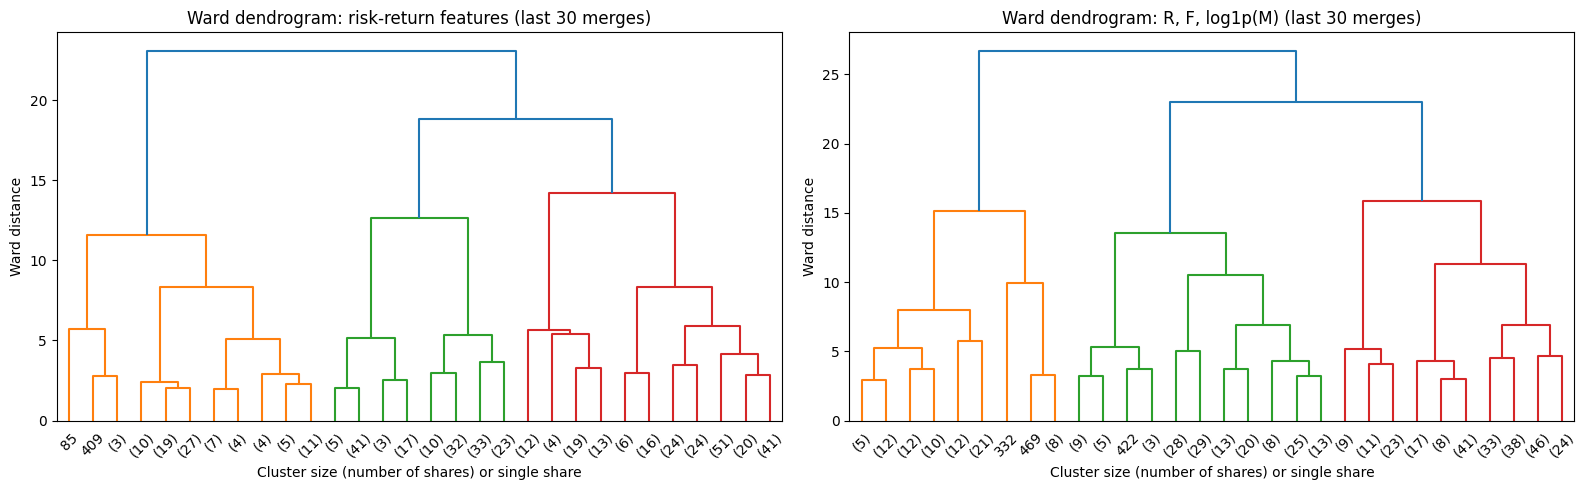

In [9]:
# --- 2.2a  One dendrogram per feature matrix (Ward linkage, Euclidean distance, standardised features) ---
link_rr = linkage(X_rr, method='ward', metric='euclidean')
link_act = linkage(X_act, method='ward', metric='euclidean')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dendrogram(link_rr, truncate_mode='lastp', p=30, show_leaf_counts=True, ax=axes[0])
axes[0].set_title('Ward dendrogram: risk-return features (last 30 merges)')
axes[0].set_xlabel('Cluster size (number of shares) or single share')
axes[0].set_ylabel('Ward distance')

dendrogram(link_act, truncate_mode='lastp', p=30, show_leaf_counts=True, ax=axes[1])
axes[1].set_title('Ward dendrogram: R, F, log1p(M) (last 30 merges)')
axes[1].set_xlabel('Cluster size (number of shares) or single share')
axes[1].set_ylabel('Ward distance')

plt.tight_layout()
plt.savefig(FIG_DIR + '/2_2_dendrograms.png', dpi=150)
plt.show()

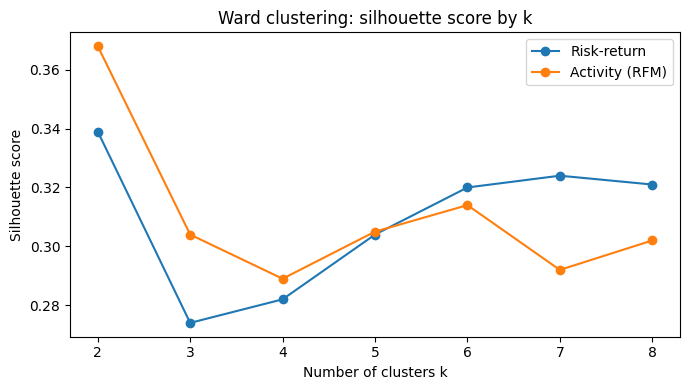

        Matrix  k  Silhouette  Smallest_cluster                     Cluster_sizes
   Risk-return  2       0.339                92                         [394, 92]
   Risk-return  3       0.274                92                    [230, 164, 92]
   Risk-return  4       0.282                48                [182, 164, 92, 48]
   Risk-return  5       0.304                48             [182, 98, 92, 66, 48]
   Risk-return  6       0.320                 5          [182, 98, 87, 66, 48, 5]
   Risk-return  7       0.324                 5      [160, 98, 87, 66, 48, 22, 5]
   Risk-return  8       0.321                 5  [160, 98, 66, 56, 48, 31, 22, 5]
Activity (RFM)  2       0.368                82                         [404, 82]
Activity (RFM)  3       0.304                82                    [250, 154, 82]
Activity (RFM)  4       0.289                43                [207, 154, 82, 43]
Activity (RFM)  5       0.305                10            [207, 154, 72, 43, 10]
Activity (RFM)  

In [10]:
# --- 2.2b  Ward clustering for k = 2 to 8 on both matrices ---
matrices = {'Risk-return': X_rr, 'Activity (RFM)': X_act}

ward_rows = []
ward_labels = {}
for name, X in matrices.items():
    for k in K_RANGE:
        labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
        ward_labels[(name, k)] = labels
        sizes = sorted(np.bincount(labels), reverse=True)
        ward_rows.append((name, k, round(silhouette_score(X, labels), 3), min(sizes), sizes))

ward_table = pd.DataFrame(ward_rows, columns=['Matrix', 'k', 'Silhouette', 'Smallest_cluster', 'Cluster_sizes'])
ward_table.to_csv(DATA_DIR + '/ward_k_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for name in matrices:
    part = ward_table[ward_table['Matrix'] == name]
    ax.plot(part['k'], part['Silhouette'], marker='o', label=name)
ax.set_xlabel('Number of clusters k')
ax.set_ylabel('Silhouette score')
ax.set_title('Ward clustering: silhouette score by k')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + '/2_2_ward_silhouette.png', dpi=150)
plt.show()

print(ward_table.to_string(index=False))

In [11]:
# --- Interpretable profiles for k = 4, 5 and 6 (original units, means) ---
profile_cols = ['Return_pct', 'Weekly_Beta', 'Recency', 'Frequency']
for name in matrices:
    for k in (4, 5, 6):
        labels = pd.Series(ward_labels[(name, k)], index=feat.index)
        prof = feat[profile_cols].groupby(labels).mean()
        prof['Median_traded_bn'] = feat['Monetary'].groupby(labels).median() / 1e9
        prof.insert(0, 'Shares', labels.value_counts().sort_index())
        print(name, '| Ward k =', k)
        print(prof.round(3).to_string())
        print()

Risk-return | Ward k = 4
   Shares  Return_pct  Weekly_Beta  Recency  Frequency  Median_traded_bn
0     164       0.287        0.601   20.646      2.780            17.649
1      92       0.632        1.298   23.674      3.196            24.184
2     182       0.132        0.973   17.714      3.011            12.985
3      48       0.200        1.628   23.542      3.229            28.698

Risk-return | Ward k = 5
   Shares  Return_pct  Weekly_Beta  Recency  Frequency  Median_traded_bn
0      92       0.632        1.298   23.674      3.196            24.184
1      48       0.200        1.628   23.542      3.229            28.698
2     182       0.132        0.973   17.714      3.011            12.985
3      98       0.422        0.710   16.908      2.704            17.649
4      66       0.088        0.439   26.197      2.894            17.701

Risk-return | Ward k = 6
   Shares  Return_pct  Weekly_Beta  Recency  Frequency  Median_traded_bn
0     182       0.132        0.973   17.714    

**Choice of the Ward cluster count (my notes)**
* Silhouette is highest at k = 2 for both matrices (0.34 and 0.37), but k = 2 only separates a small group of unusual shares (92 and 82 shares) from everyone else, which is too coarse to be useful for segmentation. Silhouette values are low overall (about 0.3), so the data has weak cluster structure and no single count is clearly "correct".
* From k = 3 upward, silhouette is similar across k (0.27 to 0.32 for risk-return, 0.29 to 0.31 for activity). I choose **k = 5 for both matrices** because the cluster sizes are workable (smallest 48 and 10 shares) and the profiles are distinct. At k = 6 and above the risk-return solution splits off a cluster of only 5 shares.
* The dendrogram height alone does not set this number. The tree supports several cuts, so the choice is based on silhouette, cluster sizes and whether the profiles can be explained.

In [12]:
# --- Selected Ward solutions ---
K_WARD_RR = 5
K_WARD_ACT = 5

assign = pd.DataFrame(index=feat.index)
assign['GICS Sector'] = feat['GICS Sector']

# Clusters are numbered 1..k in a fixed order so the numbering is repeatable:
# risk-return clusters by their mean beta (low to high), activity clusters by their mean Recency (recent to old)
for col, name, k, key in [('RR_Ward', 'Risk-return', K_WARD_RR, 'Weekly_Beta'),
                          ('Act_Ward', 'Activity (RFM)', K_WARD_ACT, 'Recency')]:
    raw = pd.Series(ward_labels[(name, k)], index=feat.index)
    new_number = feat[key].groupby(raw).mean().rank(method='first').astype(int)
    assign[col] = raw.map(new_number)

    prof = feat[['Return_pct', 'Weekly_Beta', 'Recency', 'Frequency']].groupby(assign[col]).mean()
    prof['Median_traded_bn'] = feat['Monetary'].groupby(assign[col]).median() / 1e9
    prof.insert(0, 'Shares', assign[col].value_counts().sort_index())
    print(col, '(Ward, k =', k, ')')
    print(prof.round(3).to_string())
    print()

RR_Ward (Ward, k = 5 )
         Shares  Return_pct  Weekly_Beta  Recency  Frequency  Median_traded_bn
RR_Ward                                                                       
1            66       0.088        0.439   26.197      2.894            17.701
2            98       0.422        0.710   16.908      2.704            17.649
3           182       0.132        0.973   17.714      3.011            12.985
4            92       0.632        1.298   23.674      3.196            24.184
5            48       0.200        1.628   23.542      3.229            28.698

Act_Ward (Ward, k = 5 )
          Shares  Return_pct  Weekly_Beta  Recency  Frequency  Median_traded_bn
Act_Ward                                                                       
1            207       0.247        0.926   11.140      2.942            10.785
2            154       0.338        1.010   13.682      2.864            39.695
3             43       0.281        1.008   16.837      5.372            14.430